In [2]:
from google.colab import drive
# Attempt to unmount first to ensure a clean state
drive.flush_and_unmount()

# Remove any lingering files in the mountpoint directory
!rm -rf /content/drive/*

drive.mount('/content/drive', force_remount=True)

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


In [ ]:
# To decompress files, you can use commands like 'unzip' for .zip files, 'tar -xzf' for .tar.gz, etc.
# For example:
# !unzip /content/drive/MyDrive/path/to/your_archive.zip -d /content/output_directory
# Or for .tar.gz:
DEST_DIR = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/train_images"
!mkdir -p "$DEST_DIR"
!tar -xzf /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/train_images.tgz -C "$DEST_DIR"

In [ ]:
# To decompress files, you can use commands like 'unzip' for .zip files, 'tar -xzf' for .tar.gz, etc.
# For example:
# !unzip /content/drive/MyDrive/path/to/your_archive.zip -d /content/output_directory
# Or for .tar.gz:
DEST_DIR = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/train_labels"
!mkdir -p "$DEST_DIR"
!tar -xzf /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/train_labels.tgz -C "$DEST_DIR"

In [ ]:
# To decompress files, you can use commands like 'unzip' for .zip files, 'tar -xzf' for .tar.gz, etc.
# For example:
# !unzip /content/drive/MyDrive/path/to/your_archive.zip -d /content/output_directory
# Or for .tar.gz:
DEST_DIR = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/val_images"
!mkdir -p "$DEST_DIR"
!tar -xzf /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/val_images.tgz -C "$DEST_DIR"

### Exploration des données décompressées

Nous allons maintenant explorer les fichiers que nous venons de décompresser, en particulier les images d'entraînement et le fichier GeoJSON des annotations.

In [ ]:
import geopandas as gpd
import os

In [3]:
import os

# Path to the extracted training images
train_images_path = '/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/train_images'

# List the first 10 files in the train_images directory
print(f"First 10 files in '{train_images_path}':")
# Check if the directory exists and list its content
if os.path.exists(train_images_path):
    image_files = os.listdir(train_images_path)
    if image_files:
        print(image_files[:10])
    else:
        print("No files found in train_images directory.")
else:
    print(f"Directory not found: {train_images_path}")

First 10 files in '/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/train_images':


NameError: name 'os' is not defined

Loading GeoJSON from: '/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/train_labels/xView_train.geojson'
Shape of the GeoDataFrame: (601937, 11)

Value counts for 'type_id':
type_id
73    316795
18    211664
23     12189
19      6975
24      5899
       ...  
56        70
57        64
75        51
82        28
33        17
Name: count, Length: 62, dtype: int64

First 5 rows of the GeoDataFrame:


,bounds_imcoords,edited_by,cat_id,type_id,ingest_time,index_right,image_id,point_geom,feature_id,grid_file,geometry
0,"2712,1145,2746,1177",wwoscarbecerril,1040010028371A00,73,2017-07-24 12:49:09.118000+00:00,2356,2355.tif,0101000020E6100000616E4E6406A256C03BE6ADA0D621...,374410,Grid2.shp,"POLYGON ((-90.5317 14.56604, -90.5317 14.56614..."
1,"2720,2233,2760,2288",wwoscarbecerril,1040010028371A00,73,2017-07-24 17:26:05.701000+00:00,2356,2355.tif,0101000020E6100000042D0CC705A256C0004F7071E71F...,394393,Grid2.shp,"POLYGON ((-90.53167 14.56222, -90.53167 14.562..."
2,"2687,1338,2740,1399",wwoscarbecerril,1040010028371A00,73,2017-07-24 12:45:09.081000+00:00,2356,2355.tif,0101000020E6100000B29F7E4707A256C0000AE6537921...,374031,Grid2.shp,"POLYGON ((-90.53179 14.56527, -90.53179 14.565..."
3,"2691,1201,2730,1268",wwoscarbecerril,1040010028371A00,73,2017-07-24 12:49:09.118000+00:00,2356,2355.tif,0101000020E6100000CE53137207A256C00EBF7084B521...,374409,Grid2.shp,"POLYGON ((-90.53177 14.56572, -90.53177 14.565..."
4,"2671,838,2714,869",wwoscarbecerril,1040010028371A00,73,2017-07-24 13:20:38.280000+00:00,2356,2355.tif,0101000020E610000060DE147608A256C05D6A384C6122...,377368,Grid2.shp,"POLYGON ((-90.53184 14.5671, -90.53184 14.5672..."



Visualizing the GeoDataFrame:


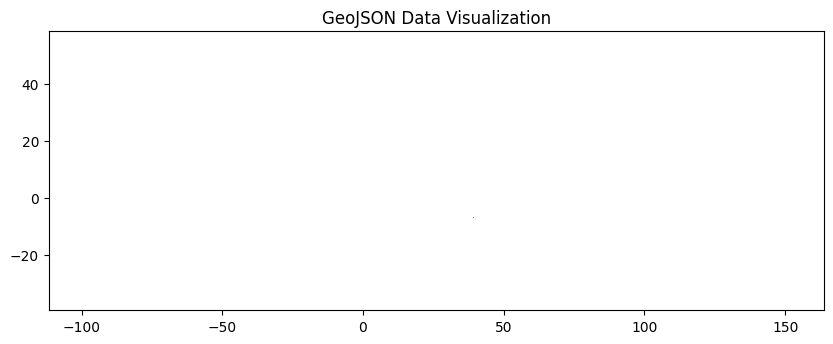

In [ ]:
# Path to the extracted training labels (GeoJSON file)
train_labels_path = '/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/train_labels/xView_train.geojson'

# Load the GeoJSON file into a GeoDataFrame
print(f"Loading GeoJSON from: '{train_labels_path}'")
if os.path.exists(train_labels_path):
    gdf = gpd.read_file(train_labels_path)
    print("Shape of the GeoDataFrame:", gdf.shape)
    print("\nValue counts for 'type_id':")
    print(gdf['type_id'].value_counts())
    print("\nFirst 5 rows of the GeoDataFrame:")
    display(gdf.head())

    # Add visualization
    import matplotlib.pyplot as plt

    print("\nVisualizing the GeoDataFrame:")
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    gdf.plot(ax=ax, cmap='viridis', markersize=5)
    ax.set_title("GeoJSON Data Visualization")
    plt.show()
else:
    print(f"GeoJSON file not found: {train_labels_path}")


Visualizing the GeoDataFrame:


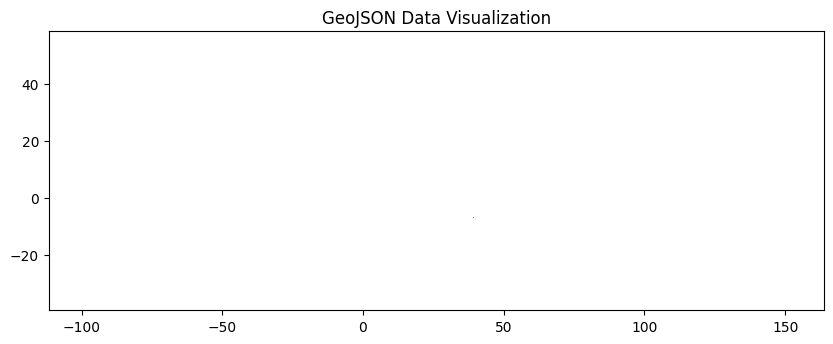

In [ ]:
import matplotlib.pyplot as plt

# Visualize the GeoDataFrame
print("\nVisualizing the GeoDataFrame:")
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
gdf.plot(ax=ax, cmap='viridis', markersize=5)
ax.set_title("GeoJSON Data Visualization")
plt.show()

In [7]:
# Decompress /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/archive
DEST_DIR_ARCHIVE = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/"
!mkdir -p "$DEST_DIR_ARCHIVE"
!unzip /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/archive.zip -d "$DEST_DIR_ARCHIVE"

Archive:  /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/archive.zip
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/DOTA/test/images/P0006.png  
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/DOTA/test/images/P0009.png  
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/DOTA/test/images/P0014.png  
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/DOTA/test/images/P0015.png  
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/DOTA/test/images/P0016.png  
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/DOTA/test/images/P0017.png  
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/

In [ ]:
# Decompress /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/dota128.zip
DEST_DIR_DOTA = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/"
!mkdir -p "$DEST_DIR_DOTA"
!unzip /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/dota128.zip -d "$DEST_DIR_DOTA"

Archive:  /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/dota128.zip
   creating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/dota128/
   creating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/dota128/images/
   creating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/dota128/images/train/
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/dota128/images/train/P2506__1024__907___524.jpg  
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/dota128/images/train/P1339__682__2094___0.jpg  
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA/dota128/images/train/P0892__1024__524___524.jpg  
  inflating: /content/drive/MyDrive/Fun_projects/Detection_objets_su

In [4]:
import kagglehub
import os

# Define the destination path in Google Drive
DEST_PATH = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/DOTA"

# Download latest version to Kaggle Hub's cache
# The 'path' argument in dataset_download is for a path *within* the dataset, not the destination.
# It returns the path to the downloaded dataset in the cache.
path_in_cache = kagglehub.dataset_download("kefanzhan/dotav1")

# Create the destination directory if it doesn't exist
!mkdir -p "$DEST_PATH"

# Move the contents from the cache to the desired destination
# Use rsync to copy contents, handling existing files gracefully and preserving structure
print(f"Moving files from {path_in_cache} to {DEST_PATH}")
!rsync -av --ignore-existing {path_in_cache}/ "{DEST_PATH}/"

print("Dataset files moved to:", DEST_PATH)

100%|██████████| 37.3G/37.3G [06:52<00:00, 97.1MB/s]

Extracting files...


Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
val/labels/P0374__1__318___0.txt
val/labels/P0374__1__318___178.txt
val/labels/P0375__1__0___0.txt
val/labels/P0377__1__0___0.txt
val/labels/P0382__1__0___0.txt
val/labels/P0382__1__0___148.txt
val/labels/P0382__1__59___0.txt
val/labels/P0382__1__59___148.txt
val/labels/P0385__1__0___0.txt
val/labels/P0396__1__0___0.txt
val/labels/P0396__1__0___153.txt
val/labels/P0396__1__59___0.txt
val/labels/P0396__1__59___153.txt
val/labels/P0402__1__0___0.txt
val/labels/P0411__1__0___0.txt
val/labels/P0411__1__0___62.txt
val/labels/P0414__1__0___0.txt
val/labels/P0414__1__0___62.txt
val/labels/P0420__1__0___0.txt
val/labels/P0420__1__0___94.txt
val/labels/P0420__1__596___0.txt
val/labels/P0420__1__596___94.txt
val/labels/P0432__1__0___0.txt
val/labels/P0454__1__0___0.txt
val/labels/P0454__1__442___0.txt
val/labels/P0457__1__0___0.txt
val/labels/P0457__1__379___0.txt
val/labels/P0466__1__0___0.txt
val/labels/P0466__1__0__